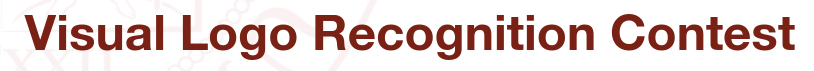

VISION AND COGNITIVE SYSTEMS A.Y. 2026/2027

The aim of the contest is to retrieve the most similar images representing logos of famous companies from a database set containing 110 images. We will consider 4 query images and use the SIFT algorithm. Model performance will be evaluated using average precision (AP) and mean average precision (mAP) metrics.
You can modify the baseline (parameters, feature matching technique, ...) and then submit your results.

In [41]:
%%capture
# Update OpenCV package
!pip install -U opencv-python
!pip install opencv-contrib-python

In [42]:
# Upload the zip folders (query.zip and database.zip)
#%%capture
import os

if not os.path.exists("query"):
    !unzip queries.zip
else:
    print("Query folder already exists. Skipping unzip.")

Query folder already exists. Skipping unzip.


In [43]:
# Upload the zip folders (query.zip and database.zip)
#%%capture
if not os.path.exists("database"):
    !unzip database.zip
else:
    print("Database folder already exists. Skipping unzip.")


Database folder already exists. Skipping unzip.


In [44]:
def resize_keep_aspect(img, max_size=400):

    h, w = img.shape[:2]

    scale = min(max_size / max(h, w), 1.0)

    new_w = int(w * scale)
    new_h = int(h * scale)

    interpolation = cv2.INTER_AREA if scale < 1 else cv2.INTER_CUBIC

    return cv2.resize(
        img,
        (new_w, new_h),
        interpolation=interpolation
    )

In [45]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

# List of query/database images
query_images = []
db_images = []
logo_names = []

# Resize images
img_size = (400, 400)

# Read query images
# Order by name
query_dir = sorted(os.listdir('query/'))
for idx, img_name in enumerate(query_dir):
  # Read image
  img = cv2.imread(os.path.join('query/', img_name))
  # Resize image
  img = resize_keep_aspect(img)
  # Save image
  query_images.append(img)
  # Save logo names (remove "_logo.txt" and capitalize)
  logo_names.append(os.path.splitext(img_name)[0][:-5].capitalize())
  #print("Image '" + img_name + "' loaded.")
print("Query images loaded!")

# Read db images
# Order by number
db_dir = sorted(os.listdir('database/'), key=lambda x: int(x.split('.')[0]))
for idx, img_name in enumerate(db_dir):
  # Read image
  img = cv2.imread(os.path.join('database/', img_name))
  # Resize image
  img = resize_keep_aspect(img)
  # Save image
  db_images.append(img)
  #print("Image '" + img_name + "' loaded.")
print("Database images loaded!")

Query images loaded!
Database images loaded!


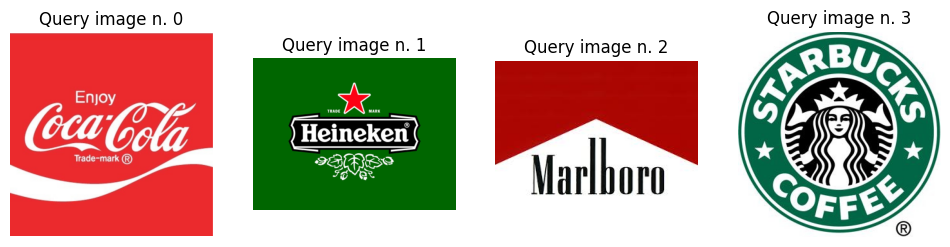

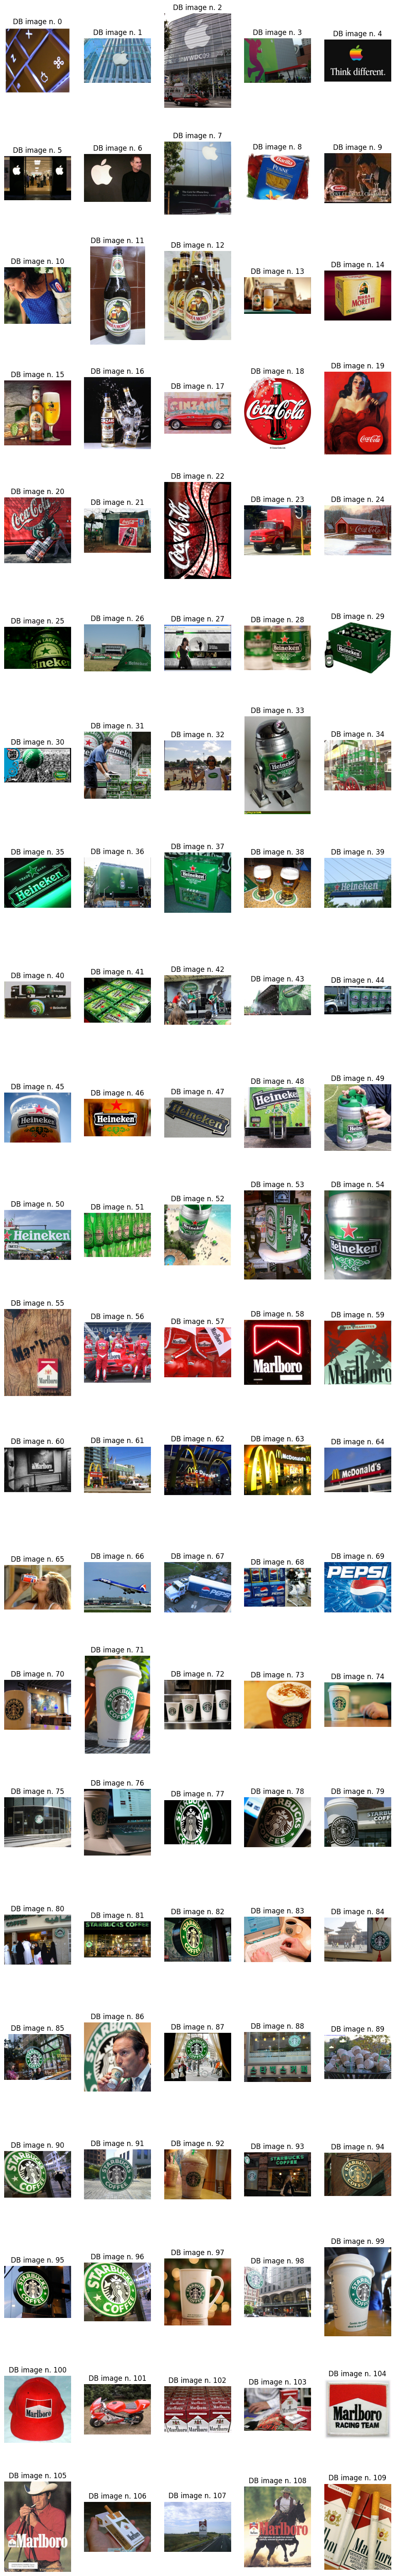

In [46]:
# Plot query images
fig = plt.figure(figsize=(12,12))
for i in range(len(query_images)):
  _ = plt.subplot(1, len(query_images), i+1), plt.title("Query image n. " + str(i))
  plt.imshow(cv2.cvtColor(query_images[i], cv2.COLOR_BGR2RGB)), plt.axis('off')

# Plot database images
fig = plt.figure(figsize=(12, 80))
for i in range(len(db_images)):
  _ = plt.subplot(int(len(db_images)/5), 5, i+1), plt.title("DB image n. " + str(i))
  plt.imshow(cv2.cvtColor(db_images[i], cv2.COLOR_BGR2RGB)), plt.axis('off')

In [47]:
# Ground-truth arrays per logo
coca_cola_GT = np.zeros(len(db_images))
marlboro_GT = np.zeros(len(db_images))
starbucks_GT = np.zeros(len(db_images))
heineken_GT = np.zeros(len(db_images))

coca_cola_GT[18:25] = 1
marlboro_GT[55:61] = 1
marlboro_GT[100:] = 1
starbucks_GT[70:100] = 1
heineken_GT[25:55] = 1

# Matrix containing ground-truth values for each query image
GT_matrix = np.vstack([coca_cola_GT, heineken_GT, marlboro_GT, starbucks_GT])
print(f"GT matrix shape: {GT_matrix.shape}")

n_coca_cola = int(coca_cola_GT.sum())
n_heineken = int(heineken_GT.sum())
n_marlboro = int(marlboro_GT.sum())
n_starbucks = int(starbucks_GT.sum())
n_others = len(db_images) - (n_coca_cola + n_heineken + n_marlboro + n_starbucks)
print(f"Number of database images (coca_cola): {n_coca_cola}")
print(f"Number of database images (heineken): {n_heineken}")
print(f"Number of database images (marlboro): {n_marlboro}")
print(f"Number of database images (starbucks): {n_starbucks}")
print(f"Number of database images (others): {n_others}")
# print(GT_matrix)

GT matrix shape: (4, 110)
Number of database images (coca_cola): 7
Number of database images (heineken): 30
Number of database images (marlboro): 16
Number of database images (starbucks): 30
Number of database images (others): 27


SIFT algorithm (default parameters)

In [48]:
def to_rootsift(des, eps=1e-7):
    if des is None:
        return None
    des = des / (des.sum(axis=1, keepdims=True) + eps)
    return np.sqrt(des).astype(np.float32)

def sift_algorithm(query_images, db_images, use_clahe=True, rootsift=True, **sift_parameters):
    detector = cv2.SIFT_create(**sift_parameters)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

    def describe(img):
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        if use_clahe:
            gray = clahe.apply(gray)
        kp, des = detector.detectAndCompute(gray, None)
        return kp, (to_rootsift(des) if rootsift else des)

    q = [describe(i) for i in query_images]
    d = [describe(i) for i in db_images]
    return [x[0] for x in q], [x[1] for x in q], [x[0] for x in d], [x[1] for x in d]

Ratio test

In [49]:
def ratio_test(query_des, db_des, ratio_thresh):

    # Brute-force matcher
    bf = cv2.BFMatcher_create(cv2.NORM_L2)

    # Matrix containing the number of matches per logo
    num_matches = np.zeros((len(query_des), len(db_des)))

    # Save matches for each query image
    logo_matches = []

    # For each query image
    for q in range(len(query_des)):
        q_matches = []

        # For each database image
        for db in range(len(db_des)):

            sel_matches = []

            # Check that descriptors are available
            if (query_des[q] is not None and
                db_des[db] is not None and
                len(query_des[q]) >= 2 and
                len(db_des[db]) >= 2):

                matches = bf.knnMatch(query_des[q], db_des[db], k=2)

                # Apply Lowe's ratio test
                for m, n in matches:
                    if m.distance < ratio_thresh * n.distance:
                        sel_matches.append(m)

            # Save number of matches
            num_matches[q, db] = len(sel_matches)

            # Save matches
            q_matches.append(sel_matches)

        logo_matches.append(q_matches)

    return num_matches, logo_matches

In [50]:
def compute_map(num_matches, GT_matrix):

    AP_all = np.zeros(len(GT_matrix))

    for i in range(len(GT_matrix)):

        # Rank database images by decreasing number of matches
        idx = np.argsort(-num_matches[i])

        # True Positives and False Positives
        TP = GT_matrix[i, idx] == 1
        FP = GT_matrix[i, idx] == 0

        TP = np.cumsum(TP)
        FP = np.cumsum(FP)

        # Precision and Recall
        prec = TP / (TP + FP)
        rec = TP / np.sum(GT_matrix[i])

        # Pascal VOC 2007 interpolated AP
        AP = 0

        for t in np.linspace(0, 1, num=11):

            p = prec[rec >= t]

            if p.size == 0:
                p = 0
            else:
                p = p.max()

            AP += p / 11

        AP_all[i] = AP

    return np.mean(AP_all)

In [51]:
def compute_knn_cache(query_des, db_des):

    bf = cv2.BFMatcher_create(cv2.NORM_L2)

    knn_cache = []

    for q in range(len(query_des)):

        q_cache = []

        for db in range(len(db_des)):

            if (query_des[q] is not None and
                len(query_des[q]) > 0 and
                db_des[db] is not None and
                len(db_des[db]) >= 2):

                matches = bf.knnMatch(
                    query_des[q],
                    db_des[db],
                    k=2
                )

                q_cache.append([
                    pair for pair in matches if len(pair) == 2
                ])

            else:
                q_cache.append([])

        knn_cache.append(q_cache)

    return knn_cache

In [52]:
def geometric_inliers(matches, qkp, dbkp, thresh=5.0, min_inliers=5):
    if len(matches) < min_inliers:
        return 0, []
    src = np.float32([qkp[m.queryIdx].pt for m in matches]).reshape(-1,1,2)
    dst = np.float32([dbkp[m.trainIdx].pt for m in matches]).reshape(-1,1,2)
    M, mask = cv2.estimateAffinePartial2D(src, dst, method=cv2.RANSAC,
                                          ransacReprojThreshold=thresh)
    if M is None:
        return 0, []
    mask = mask.ravel().astype(bool)
    n = int(mask.sum())
    if n < min_inliers:
        return 0, []
    return n, [m for m, k in zip(matches, mask) if k]

def apply_ratio_test(knn_cache, ratio_thresh, query_kps=None, db_kps=None,
                     ransac_thresh=5.0, min_inliers=5):
    num_matches = np.zeros((len(knn_cache), len(knn_cache[0])))
    logo_matches = []
    for q in range(len(knn_cache)):
        q_matches = []
        for db in range(len(knn_cache[q])):
            sel = [m for m, n in knn_cache[q][db] if m.distance < ratio_thresh * n.distance]
            # un point de la DB ne doit être matché qu'une fois (on garde le meilleur)
            best = {}
            for m in sel:
                if m.trainIdx not in best or m.distance < best[m.trainIdx].distance:
                    best[m.trainIdx] = m
            sel = list(best.values())
            if query_kps is not None:
                n_in, inl = geometric_inliers(sel, query_kps[q], db_kps[db],
                                              ransac_thresh, min_inliers)
                num_matches[q, db] = n_in + 0.001 * len(sel)  # 2e terme = départage les égalités
                q_matches.append(inl)
            else:
                num_matches[q, db] = len(sel)
                q_matches.append(sel)
        logo_matches.append(q_matches)
    return num_matches, logo_matches

In [53]:
from itertools import product
import itertools

param_grid = {
    "nfeatures": [0, 1000],
    "contrastThreshold": [0.02, 0.03, 0.04, 0.06],
    "edgeThreshold": [10, 15],
}
ratio_values = np.arange(0.70, 0.91, 0.02)

In [54]:
import pandas as pd
import json

results = []

param_names = list(param_grid.keys())
param_combinations = list(product(*param_grid.values()))

best = {"mAP": -1}

for i, params in enumerate(param_combinations):

    sift_params = dict(zip(param_names, params))

    print(f"\nConfiguration {i+1}/{len(param_combinations)}")
    print("SIFT parameters:", sift_params)

    # Step 1: Compute SIFT features
    query_kps, query_des, db_kps, db_des = sift_algorithm(
        query_images,
        db_images,
        **sift_params
    )

    # Step 2: Compute KNN matches only once
    knn_cache = compute_knn_cache(query_des, db_des)

    # Step 3: Test all Lowe ratios
    for ratio in ratio_values:

        num_matches, logo_matches = apply_ratio_test(knn_cache, ratio, query_kps, db_kps)

        # Step 4: Evaluate mAP
        map_score = compute_map(num_matches, GT_matrix)

        results.append({
            "sift_params": sift_params.copy(),
            "ratio_thresh": ratio,
            "mAP": map_score
        })

        # Store best configuration
        if map_score > best["mAP"]:

            best = {
                "mAP": map_score,
                "params": sift_params.copy(),
                "ratio": ratio,
                "num_matches": num_matches.copy(),
                "logo_matches": logo_matches,
                "query_kps": query_kps,
                "db_kps": db_kps
            }

    # Save progress every 10 SIFT configurations
    if (i + 1) % 10 == 0:
        pd.DataFrame(results).to_csv(
            "grid_search_progress.csv",
            index=False
        )

# Restore best configuration
num_matches = best["num_matches"]
logo_matches = best["logo_matches"]
query_kps = best["query_kps"]
db_kps = best["db_kps"]

# Save final results
results_df = pd.DataFrame(results)
results_df.to_csv("grid_search_results.csv", index=False)

# Save best configuration
with open("best_params.json", "w") as f:
    json.dump({
        "mAP": best["mAP"],
        "sift_params": best["params"],
        "ratio_thresh": best["ratio"]
    }, f, indent=4)

print("\nBEST CONFIGURATION")
print("mAP:", best["mAP"])
print("SIFT parameters:", best["params"])
print("Lowe ratio:", best["ratio"])


Configuration 1/16
SIFT parameters: {'nfeatures': 0, 'contrastThreshold': 0.02, 'edgeThreshold': 10}

Configuration 2/16
SIFT parameters: {'nfeatures': 0, 'contrastThreshold': 0.02, 'edgeThreshold': 15}

Configuration 3/16
SIFT parameters: {'nfeatures': 0, 'contrastThreshold': 0.03, 'edgeThreshold': 10}

Configuration 4/16
SIFT parameters: {'nfeatures': 0, 'contrastThreshold': 0.03, 'edgeThreshold': 15}

Configuration 5/16
SIFT parameters: {'nfeatures': 0, 'contrastThreshold': 0.04, 'edgeThreshold': 10}

Configuration 6/16
SIFT parameters: {'nfeatures': 0, 'contrastThreshold': 0.04, 'edgeThreshold': 15}

Configuration 7/16
SIFT parameters: {'nfeatures': 0, 'contrastThreshold': 0.06, 'edgeThreshold': 10}

Configuration 8/16
SIFT parameters: {'nfeatures': 0, 'contrastThreshold': 0.06, 'edgeThreshold': 15}

Configuration 9/16
SIFT parameters: {'nfeatures': 1000, 'contrastThreshold': 0.02, 'edgeThreshold': 10}

Configuration 10/16
SIFT parameters: {'nfeatures': 1000, 'contrastThreshold': 

In [55]:
results_df = pd.read_csv("grid_search_results.csv")

results_df = results_df.sort_values(
    by="mAP",
    ascending=False
)

display(results_df.head(10))

,sift_params,ratio_thresh,mAP
5,"{'nfeatures': 0, 'contrastThreshold': 0.02, 'e...",0.80,0.890001
115,"{'nfeatures': 1000, 'contrastThreshold': 0.03,...",0.80,0.888157
38,"{'nfeatures': 0, 'contrastThreshold': 0.03, 'e...",0.80,0.885046
16,"{'nfeatures': 0, 'contrastThreshold': 0.02, 'e...",0.80,0.883591
116,"{'nfeatures': 1000, 'contrastThreshold': 0.03,...",0.82,0.879006
93,"{'nfeatures': 1000, 'contrastThreshold': 0.02,...",0.80,0.878802
60,"{'nfeatures': 0, 'contrastThreshold': 0.04, 'e...",0.80,0.878402
82,"{'nfeatures': 0, 'contrastThreshold': 0.06, 'e...",0.80,0.878160
105,"{'nfeatures': 1000, 'contrastThreshold': 0.02,...",0.82,0.877839
27,"{'nfeatures': 0, 'contrastThreshold': 0.03, 'e...",0.80,0.877131


In [56]:
results_df["contrastThreshold"] = results_df[
    "sift_params"
].apply(lambda x: eval(x)["contrastThreshold"])

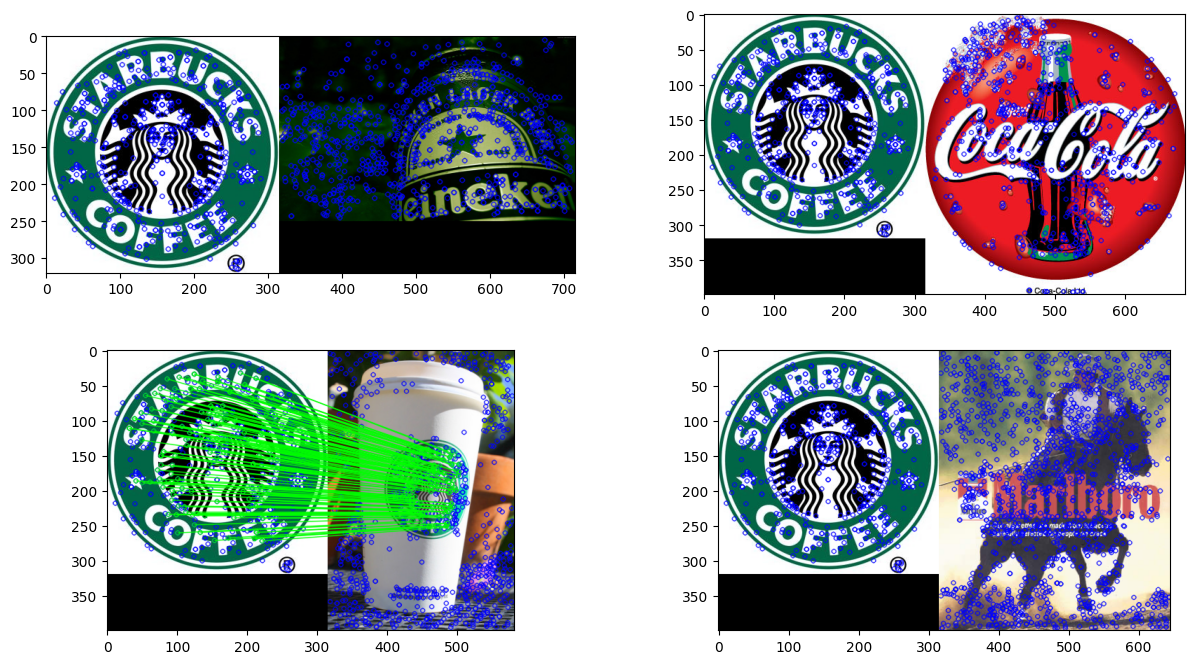

In [57]:
# Draw some matches for Starbucks logo
_  = plt.figure(figsize=(15, 8))
draw_params = dict(matchColor=(0, 255, 0), singlePointColor=(255, 0, 0), flags=0)
plt_list = [25, 18, 71, 108]
for idx, n in enumerate(plt_list):
  img_matches = cv2.drawMatches(query_images[3], query_kps[3], db_images[n], db_kps[n], logo_matches[3][n], None, **draw_params)
  _ = plt.subplot(2, 2, idx+1), plt.imshow(cv2.cvtColor(img_matches, cv2.COLOR_BGR2RGB))

# **Performance Evaluation**

The performance of the model will be evaluated in terms of precision, recall and average precision.

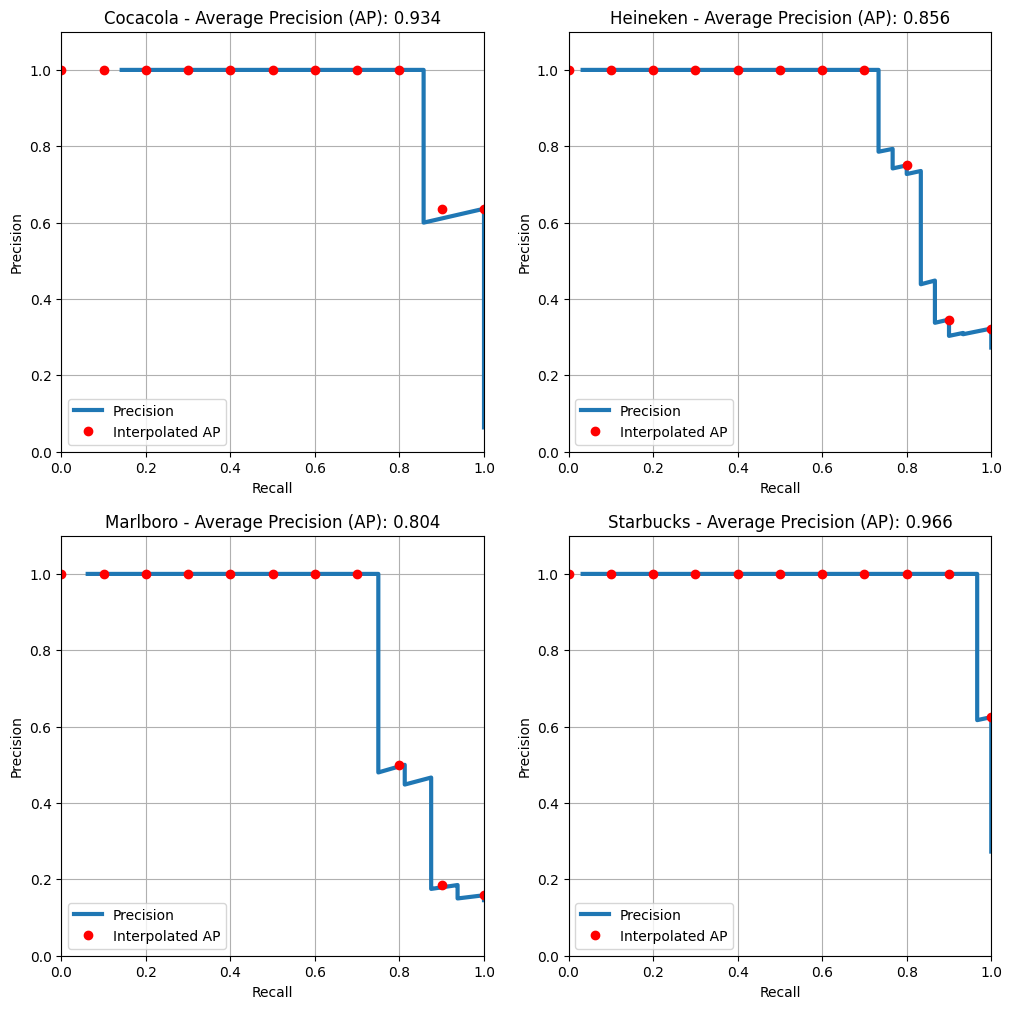

In [58]:
# Average precision for each logo
AP_all = np.zeros(len(query_images))

_ = plt.figure(figsize=(12, 12))
for i in range(len(query_images)):
  # Rank images in descending order according to the number of detected matches
  # The idx (corresponding to database images) which have the largest number of valid matches will be situated towards
  # the start of the array
  # The idx containing the least number of valid matches will be situated towards the end of the array
  # In this manner, we arrange predictions based on its validity or confidence (here, measured by the number of matches)
  idx = np.argsort(-num_matches[i])

  # True Positives
  TP = GT_matrix[i, idx] == 1

  # False Positives
  FP = GT_matrix[i, idx] == 0

  # TP and FP for each first k database images --> using np.cumsum gives us different "clusters" of matched database images,
  # ordered by number of matches. NB: TP + FP = k for each k
  # Note that as we go from the start to the end of the array, we are effectively varying the confidence threshold
  # (here, we use the number of matches as our confidence measure).
  # This is possible since the idx is sorted, and correspondingly, so are the TP and FP arrays
  TP = np.cumsum(TP)
  FP = np.cumsum(FP)

  # Precision/Recall for each k
  prec = TP / (TP + FP)
  rec = TP / np.sum(GT_matrix[i])

  # (Interpolated) Average precision (as in Pascal VOC2007)
  AP = 0
  interp_prec = []
  # We evaluate the precision at 11 recall values to reduce ''wiggles'' in the precision/recall curve
  for t in np.linspace(0, 1, num=11):
    p = prec[rec >= t]
    if p.size == 0:
      p = 0
    else:
      p = p.max()
    interp_prec.append(p)
    AP = AP + p/11
  AP_all[i] = AP

  # Plot precision/recall
  _ = plt.subplot(2, 2, i+1)
  plt.title(f"{logo_names[i]} - Average Precision (AP): {AP:.3f}")
  _ = plt.plot(rec, prec, '-', linewidth=3)
  _ = plt.plot(np.linspace(0, 1, num=11), interp_prec, 'o', color='red', linewidth=2)
  plt.legend(['Precision', 'Interpolated AP'])
  plt.grid('on')
  plt.xlabel('Recall'), plt.ylabel('Precision')
  plt.axis((0,1,0,1.1))

In [59]:
# Print results
print('BASELINE RESULTS')
print("Average Precision (AP):\n")
for i in range(len(query_images)):
  print(f'{logo_names[i]:9s}  ===>' + ' ' * 2 + f'{AP_all[i]:.3f}')

print(f"\nMean Average Precision (mAP) ===> {np.mean(AP_all):.3f}")

BASELINE RESULTS
Average Precision (AP):

Cocacola   ===>  0.934
Heineken   ===>  0.856
Marlboro   ===>  0.804
Starbucks  ===>  0.966

Mean Average Precision (mAP) ===> 0.890
